In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.metrics import mean_squared_error,r2_score

In [2]:
df=pd.read_csv('/home/backup/ml_datasets/auto_mpg.csv')
print(df.head())
print(df.isnull().sum())
print(df.info())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):


In [3]:
#droppping car name
df=df.drop('name',axis=1)

In [4]:
#parameter selection
x=df[['displacement']]
y=df['mpg']
print("Done")

Done


In [5]:
#Split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("Done Split")
print(x_train.head())
print(x_test.head())

Done Split
     displacement
3           304.0
18           97.0
376          91.0
248          91.0
177         115.0
     displacement
198          91.0
396         120.0
33          232.0
208         318.0
93          318.0


In [6]:
degree=2
poly_features=PolynomialFeatures(degree=2)
x_train_poly=poly_features.fit_transform(x_train)
x_test_poly=poly_features.transform(x_test)
poly_reg=LinearRegression()
poly_reg.fit(x_train_poly,y_train)
y_pred=poly_reg.predict(x_test_poly)
predictions=pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
print(predictions)

     Actual  Predicted
198    33.0  31.003632
396    28.0  28.019267
33     19.0  19.140687
208    13.0  15.177643
93     14.0  15.177643
..      ...        ...
249    19.9  17.578159
225    17.5  18.106031
367    28.0  28.814378
175    29.0  31.111570
285    17.0  15.617625

[80 rows x 2 columns]


In [7]:
#Intercept and slope
print(f"Intercept:{poly_reg.intercept_}\n")
print(f"Coefficients\nCoefficient 1:{poly_reg.coef_[1]}\nCoefficient 2:{poly_reg.coef_[2]}\n")

Intercept:42.19890515572759

Coefficients
Coefficient 1:-0.13827949203565096
Coefficient 2:0.0001676319836646234



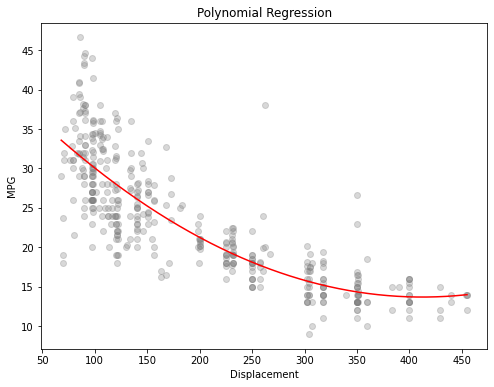

In [8]:
plt.figure(figsize=(8,6))
plt.scatter(x,y,alpha=0.3,color="gray")
x_range=pd.DataFrame(
    np.linspace(x['displacement'].min(),x['displacement'].max(),500),
    columns=['displacement']
)
x_range_poly=poly_features.transform(x_range)
y_range=poly_reg.predict(x_range_poly)
plt.plot(x_range,y_range,color='red',label=f'Degree{degree}')
plt.title("Polynomial Regression")
plt.xlabel("Displacement")
plt.ylabel("MPG")
plt.show()

In [9]:
#Polymonial Regression
mse_poly=mean_squared_error(y_test,y_pred)
rmse_poly=np.sqrt(mse_poly)
r2_poly=r2_score(y_test,y_pred)
print(f"MSE:{mse_poly}\nRMSE:{rmse_poly}\nR2 Score:{r2_poly}\n")

MSE:15.10735356108076
RMSE:3.8868179222959185
R2 Score:0.7190189176110284



In [10]:
degree=7
poly_features3=PolynomialFeatures(degree)
x_train_poly3=poly_features3.fit_transform(x_train)
x_test_poly3=poly_features3.transform(x_test)
poly_reg_3=LinearRegression()
poly_reg_3.fit(x_train_poly3,y_train)
y_pred3=poly_reg_3.predict(x_test_poly3)
predictions3=pd.DataFrame({'Actual':y_test,'Predicted':y_pred3})
print(predictions3)

     Actual  Predicted
198    33.0  31.234014
396    28.0  27.933378
33     19.0  19.123018
208    13.0  15.495690
93     14.0  15.495690
..      ...        ...
249    19.9  17.944522
225    17.5  18.354704
367    28.0  28.850675
175    29.0  31.343503
285    17.0  16.053368

[80 rows x 2 columns]


In [11]:
#Intercept and slope
print(f"Intercept:{poly_reg_3.intercept_}\n")
print(f"Coefficients\nCoefficient 1:{poly_reg_3.coef_[1]}\nCoefficient 2:{poly_reg_3.coef_[2]}\n")
#Error
mse_poly_3=mean_squared_error(y_test,y_pred3)
rmse_poly_3=np.sqrt(mse_poly_3)
r2_poly_3=r2_score(y_test,y_pred3)
print(f"MSE:{mse_poly_3}\nRMSE:{rmse_poly_3}\nR2 Score:{r2_poly_3}\n")

Intercept:36.19012863565462

Coefficients
Coefficient 1:-5.18292002925869e-09
Coefficient 2:-2.513892300409867e-07

MSE:14.919468839579093
RMSE:3.862572826443418
R2 Score:0.7225133782522284



In [12]:
degree=5
poly_features_5=PolynomialFeatures(degree)
x_train_poly_5=poly_features_5.fit_transform(x_train)
x_test_poly_5=poly_features_5.transform(x_test)
poly_reg_5=LinearRegression()
poly_reg_5.fit(x_train_poly_5,y_train)
y_pred_5=poly_reg_5.predict(x_test_poly_5)
predictions_5=pd.DataFrame({'Actual':y_test,'Predicted':y_pred_5})
print(predictions_5)

     Actual  Predicted
198    33.0  31.177736
396    28.0  28.081146
33     19.0  18.866843
208    13.0  15.751068
93     14.0  15.751068
..      ...        ...
249    19.9  17.713016
225    17.5  18.092258
367    28.0  28.962292
175    29.0  31.276069
285    17.0  16.194724

[80 rows x 2 columns]


In [13]:
#Intercept and slope
print(f"Intercept:{poly_reg_5.intercept_}\n")
print(f"Coefficients\nCoefficient 1:{poly_reg_5.coef_[1]}\nCoefficient 2:{poly_reg_5.coef_[2]}\n")
#Error
mse_poly_5=mean_squared_error(y_test,y_pred_5)
rmse_poly_5=np.sqrt(mse_poly_5)
r2_poly_5=r2_score(y_test,y_pred_5)
print(f"MSE:{mse_poly_5}\nRMSE:{rmse_poly_5}\nR2 Score:{r2_poly_5}\n")

Intercept:29.503656430134495

Coefficients
Coefficient 1:0.23496810003121504
Coefficient 2:-0.0037485506154608444

MSE:15.230931613467419
RMSE:3.9026826175680003
R2 Score:0.7167204942122025



In [29]:
model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
mse_l=mean_squared_error(y_test,y_pred)
rmse_l=np.sqrt(mse_l)
r2_l=r2_score(y_test,y_pred)
print(f"Intercept:{model.intercept_}")
print(f"Slope:{model.coef_}")
print(f"MSE:{mse_l}\nRMSE:{rmse_l}\nR2 Score:{r2_l}\n")

Intercept:35.45349527608239
Slope:[-0.06172521]
MSE:18.102543998358946
RMSE:4.254708450453326
R2 Score:0.6633114869465596



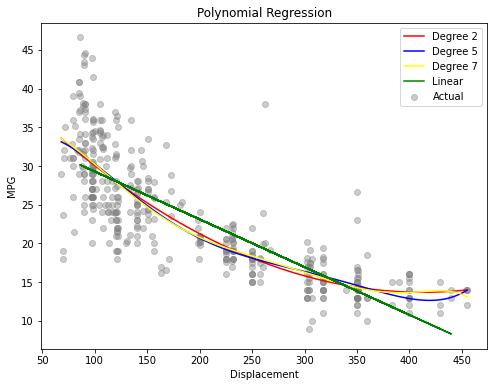

In [22]:
x_range=pd.DataFrame(
    np.linspace(x['displacement'].min(),x['displacement'].max(),100),
    columns=['displacement'])
x_range_poly=poly_features.transform(x_range)
y_range=poly_reg.predict(x_range_poly)
x_range_poly_3=poly_features3.transform(x_range)
y_range_3=poly_reg_3.predict(x_range_poly_3)
x_range_5=poly_features_5.transform(x_range)
y_range_5=poly_reg_5.predict(x_range_5)
#plotting degree 2 and 3
plt.figure(figsize=(8,6))
plt.scatter(x,y,alpha=0.4,color='gray',label="Actual")
plt.plot(x_range,y_range,color='red',label="Degree 2")
plt.plot(x_range,y_range_5,color='blue',label="Degree 5")
plt.plot(x_range,y_range_3,color='yellow',label="Degree 7")
plt.plot(x_test,y_pred,color='green',label="Linear")
plt.xlabel("Displacement")
plt.ylabel("MPG")
plt.title("Polynomial Regression")
plt.legend()
plt.show()


In [28]:
#Comparison
compd=pd.DataFrame({
    'Case':["Linear","Degree 2","Degree 5","Degree 7"],
    'MSE':[mse_l,mse_poly,mse_poly_5,mse_poly_3],
    'RMSE':[rmse_l,rmse_poly,rmse_poly_5,rmse_poly_3],
    'R2 Score':[r2_l,r2_poly,r2_poly_5,r2_poly_3]
})
print(compd)

       Case        MSE      RMSE  R2 Score
0    Linear  18.102544  4.254708  0.663311
1  Degree 2  15.107354  3.886818  0.719019
2  Degree 5  15.230932  3.902683  0.716720
3  Degree 7  14.919469  3.862573  0.722513
